# Chapter 6. What the leftovers confess

*Where each model fails; the residual tells.*

A fitted line always looks fine on a scatter plot from a distance. The residuals, what each point missed by, are where a wrong shape confesses. This chapter uses real public data: the UCI Auto MPG table of 398 cars from the 1970s and early 1980s, where fuel economy (miles per gallon) falls as horsepower rises, along a curve.

By the end you can draw a residual plot, read a bow in it as "the straight line missed a curve", fix it with horsepower squared, and say where each fix and each model stops working.

**Search terms:** residual plot, regression diagnostics, non-linear relationship, polynomial features, extrapolation.

Dataset: UCI Auto MPG, R. Quinlan, licensed CC BY 4.0, archive.ics.uci.edu/dataset/9/auto+mpg (verified 28 October 2026).

In [1]:
# Tools for this notebook, and one helper that prints a check as PASS or FAIL.
import io, zipfile, pathlib, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

def check(label, ok):
    print(("PASS  " if ok else "FAIL  ") + label)

# Load the day's public dataset once; later runs read the cached copy.
CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def load_cars():
    """UCI Auto MPG (CC BY 4.0): whitespace-separated, no header, '?' where horsepower is missing."""
    f = CACHE / "auto-mpg.data"
    if not f.exists():
        z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(
            "https://archive.ics.uci.edu/static/public/9/auto+mpg.zip", timeout=60).read()))  # verified 28 October 2026
        f.write_bytes(z.read("auto-mpg.data"))
    names = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year", "origin", "car_name"]
    return pd.read_csv(f, sep=r"\s+", names=names, na_values="?")

raw = load_cars()
cars = raw.dropna(subset=["horsepower"]).reset_index(drop=True)
print(f"{len(raw)} cars, {raw['horsepower'].isna().sum()} with no horsepower, {len(cars)} kept")
check("six cars have no horsepower and are dropped", raw["horsepower"].isna().sum() == 6 and len(cars) == 392)

398 cars, 6 with no horsepower, 392 kept
PASS  six cars have no horsepower and are dropped


## Fit the straight line first

**Predict before you run.** If the true shape is a curve that flattens at high horsepower, the straight line's residuals will be (a) scattered evenly around zero (b) positive at both ends and negative in the middle (c) negative everywhere

In [2]:
# Fit mpg on horsepower with a straight line and look at the residuals against horsepower.
from sklearn.linear_model import LinearRegression
X1 = cars[["horsepower"]]
line = LinearRegression().fit(X1, cars["mpg"])
cars["resid_line"] = cars["mpg"] - line.predict(X1)
print(f"mpg = {line.intercept_:.2f} {line.coef_[0]:+.4f} x horsepower")
bins = pd.qcut(cars["horsepower"], 5)
bow = cars.groupby(bins, observed=True)["resid_line"].mean().round(2)
print("mean residual in five horsepower bands, lowest to highest:"); print(bow.to_string())
check("the bow: both end bands sit above zero and the middle band below", bow.iloc[0] > 1 and bow.iloc[-1] > 0 and bow.iloc[2] < -1)

mpg = 39.94 -0.1578 x horsepower
mean residual in five horsepower bands, lowest to highest:
horsepower
(45.999, 72.0]    2.73
(72.0, 88.0]      0.04
(88.0, 100.0]    -2.18
(100.0, 140.0]   -1.74
(140.0, 230.0]    0.81
PASS  the bow: both end bands sit above zero and the middle band below


**What happened.** The answer is (b). The cheapest-horsepower cars beat the line by 2.7 mpg on average, the middle band falls 2.2 below it, and the most powerful cars sit back above it. A pattern like that is the line confessing that the real relationship bends.

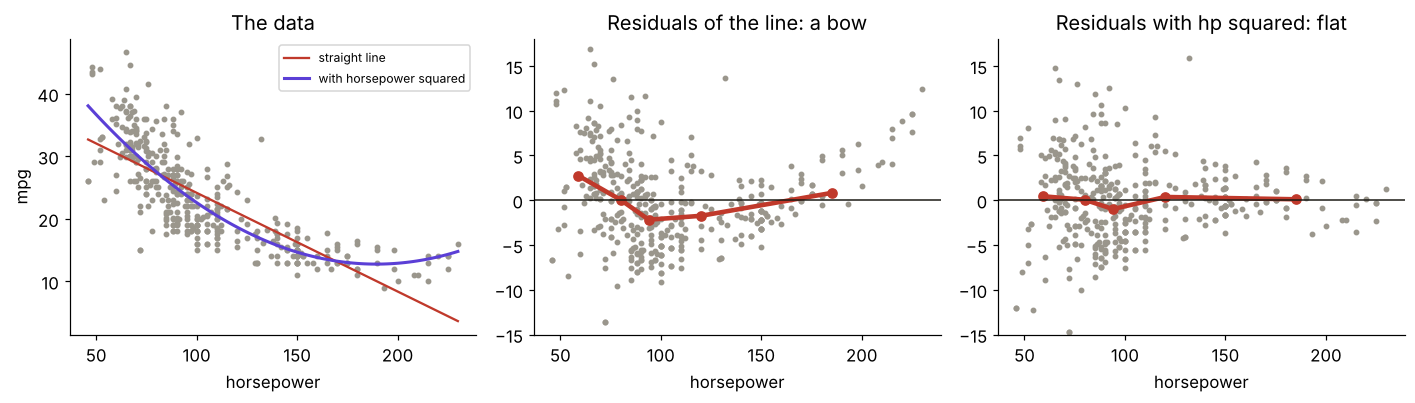

band means after the fix: [0.44, 0.05, -0.99, 0.36, 0.1]
typical miss: line 4.89 mpg, with hp squared 4.36 mpg
PASS  the fix shrinks the widest band mean below 1 mpg
PASS  the fix lowers the typical miss


In [3]:
# Add horsepower squared, refit, and draw both residual plots side by side.
cars["hp2"] = cars["horsepower"] ** 2
curve = LinearRegression().fit(cars[["horsepower", "hp2"]], cars["mpg"])
cars["resid_curve"] = cars["mpg"] - curve.predict(cars[["horsepower", "hp2"]])
bow2 = cars.groupby(bins, observed=True)["resid_curve"].mean().round(2)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
grid = pd.DataFrame({"horsepower": np.linspace(46, 230, 100)}); grid["hp2"] = grid["horsepower"] ** 2
axes[0].scatter(cars["horsepower"], cars["mpg"], s=8, color="#9A968C")
axes[0].plot(grid["horsepower"], line.predict(grid[["horsepower"]]), color="#C0392B", label="straight line")
axes[0].plot(grid["horsepower"], curve.predict(grid), color="#5B3FD6", lw=2, label="with horsepower squared")
axes[0].set_xlabel("horsepower"); axes[0].set_ylabel("mpg"); axes[0].legend(fontsize=8); axes[0].set_title("The data")
for ax, col, title in [(axes[1], "resid_line", "Residuals of the line: a bow"), (axes[2], "resid_curve", "Residuals with hp squared: flat")]:
    ax.scatter(cars["horsepower"], cars[col], s=8, color="#9A968C")
    means = cars.groupby(bins, observed=True)[col].mean()
    ax.plot([iv.mid for iv in means.index], means.values, color="#C0392B", lw=3, marker="o")
    ax.axhline(0, color="#1C1B16", lw=1); ax.set_ylim(-15, 18); ax.set_title(title); ax.set_xlabel("horsepower")
plt.tight_layout(); plt.show()
print("band means after the fix:", bow2.tolist())
rmse = lambda r: float(np.sqrt((r ** 2).mean()))
print(f"typical miss: line {rmse(cars['resid_line']):.2f} mpg, with hp squared {rmse(cars['resid_curve']):.2f} mpg")
check("the fix shrinks the widest band mean below 1 mpg", bow2.abs().max() < 1.0)
check("the fix lowers the typical miss", rmse(cars["resid_curve"]) < rmse(cars["resid_line"]))

## Where does each model fail?

| Model | Where it fails | What the residuals or outputs show | The fix, and when it comes |
|---|---|---|---|
| Straight line | the truth curves | a bow: positive at the ends, negative in the middle | a squared term today; Wednesday turns this into feature engineering |
| Line with a squared term | outside the data | it predicts mpg rising again past about 190 horsepower | never quote it beyond the range it was fitted on |
| Logistic regression | the chance rises at both ends of an input | one S can only go one way, so the middle is over- or under-called | the same squared-term idea, or bands of the input |
| Any model | the input is missing or wrong | six cars have `?` for horsepower | decide and record what happens to them before fitting |

In [4]:
# The squared term's own failure: ask it about engines beyond the data.
for hp in (150, 200, 230, 300):
    g = pd.DataFrame({"horsepower": [hp], "hp2": [hp * hp]})
    print(f"{hp} hp: line says {line.predict(g[['horsepower']])[0]:5.1f} mpg, curve says {curve.predict(g)[0]:5.1f} mpg")
check("the curve predicts more mpg at 300 hp than at 200 hp, which no engine does", curve.predict(pd.DataFrame({"horsepower": [300], "hp2": [90000]}))[0] > curve.predict(pd.DataFrame({"horsepower": [200], "hp2": [40000]}))[0])

150 hp: line says  16.3 mpg, curve says  14.7 mpg
200 hp: line says   8.4 mpg, curve says  12.9 mpg
230 hp: line says   3.6 mpg, curve says  14.8 mpg
300 hp: line says  -7.4 mpg, curve says  27.8 mpg
PASS  the curve predicts more mpg at 300 hp than at 200 hp, which no engine does


**The rule.** Read the residuals before you trust the fit. A pattern in them (a bow, a fan, bands) is a shape the model missed; random scatter around zero is what a good fit leaves behind. **The flip:** a flat residual plot is evidence for the shape inside the data's range only; outside it, even the curve that fixed the bow fails.

## What did this chapter establish?

| Question | Answer |
|---|---|
| What did the line's residuals show? | a bow: +2.7 mpg in the lowest horsepower band, -2.2 in the middle, +0.8 at the top |
| What fixed it? | horsepower squared: the band means fall within 1 mpg, the typical miss from 4.89 to 4.36 mpg |
| Where does the fix fail? | beyond about 190 horsepower it predicts mileage rising again |
| Where does logistic regression fail? | where the chance rises at both ends of an input |

**Interview line:** "I plot residuals against the input and against the prediction; a bow means the shape is wrong, a fan means the spread changes, and I never quote a polynomial outside the range it was fitted on."